In [1]:
!pip -q install ultralytics
from google.colab import drive, files
drive.mount('/content/drive')
import json, re, random, cv2, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

ROOT = Path('/content/drive/MyDrive/Objectdetection')
yolo = YOLO(str(ROOT / 'runs/yolov8s_grid/weights/best.pt'))
print(len(yolo.names), 'classes', list(yolo.names.values())[:3])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 10.3 MB/s eta 0:00:00
Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
73 classes ['OBJ001', 'OBJ002', 'OBJ003']


In [2]:
try:
    url = 'https://docs.google.com/spreadsheets/d/e/2PACX-1vTmDZE3bv_sVu27u23-ibTOTNm8F3Rl982n6r86LdOEudsA20Joq4Y1LEqZ1olfRr9yO5LO92H-SaUV/pub?output=csv'
    ids = pd.read_csv(url); ids.columns = ids.columns.str.strip()
    id_to_name = {str(r.OBJECT_ID).strip(): str(r.OBJECT_NAME).strip() for r in ids.itertuples()}
except Exception:
    id_to_name = {k: v.strip('. ') for k, v in json.load(open(ROOT / 'class_prompts.json')).items()}
print(len(id_to_name), 'names loaded')

73 names loaded


In [3]:
def identify_single(path, imgsz=512):
    r = yolo.predict(path, imgsz=imgsz, conf=0.15, iou=0.5, agnostic_nms=True, verbose=False)[0]
    if len(r.boxes) == 0:
        print("No object detected"); return
    order = r.boxes.conf.argsort(descending=True).tolist()
    for rank, i in enumerate(order[:3], 1):
        oid = yolo.names[int(r.boxes.cls[i])]
        print(f"{rank}. {oid} | {id_to_name.get(oid, '?')} | {float(r.boxes.conf[i]):.2f}")
    x1, y1, x2, y2 = map(int, r.boxes.xyxy[order[0]].tolist())
    img = r.orig_img.copy(); cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

def detect_multi(path, imgsz=1024, conf=0.35, iou=0.5):
    r = yolo.predict(path, imgsz=imgsz, conf=conf, iou=iou, verbose=False)[0]
    img, rows = r.orig_img.copy(), []
    for b in r.boxes:
        oid = yolo.names[int(b.cls)]; name = id_to_name.get(oid, '?')
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        rows.append({'ID': oid, 'Name': name, 'Conf': round(float(b.conf), 2), 'Box (x1,y1,x2,y2)': (x1, y1, x2, y2)})
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, f"{oid} {name} {float(b.conf):.2f}", (x1, max(y1 - 8, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    plt.figure(figsize=(10, 8)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
    return pd.DataFrame(rows)

In [4]:
imgs = sorted(p for p in (ROOT / 'data/images/test').iterdir() if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
random.Random(0).shuffle(imgs); imgs = imgs[:300]
truth = [f"OBJ{int(re.match(r'OBJ(\d+)', p.stem.upper()).group(1)):03d}" for p in imgs]

rows = []
for s in [320, 448, 512, 640, 1024]:
    hit = found = 0
    for p, t in zip(imgs, truth):
        r = yolo.predict(str(p), imgsz=s, conf=0.15, iou=0.5, agnostic_nms=True, verbose=False)[0]
        if len(r.boxes):
            found += 1
            hit += yolo.names[int(r.boxes.cls[int(r.boxes.conf.argmax())])] == t
    rows.append({'imgsz': s, 'top1_acc': round(hit / len(imgs), 3), 'detected': round(found / len(imgs), 3)})
display(pd.DataFrame(rows))

,imgsz,top1_acc,detected
0,320,0.890,0.917
1,448,0.893,0.930
2,512,0.887,0.920
3,640,0.883,0.947
4,1024,0.813,0.903


Saving OBJ048_002.jpg to OBJ048_002.jpg

== OBJ048_002.jpg
1. OBJ048 | Wireless powerbank | 0.99
2. OBJ048 | Wireless powerbank | 0.97
3. OBJ048 | Wireless powerbank | 0.93


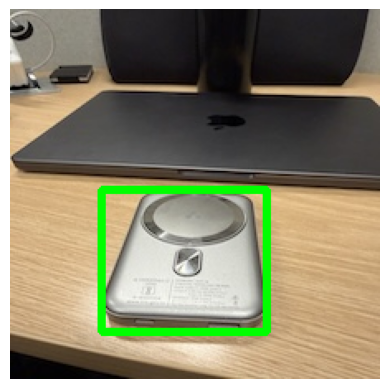

In [5]:
up = files.upload()
for f in up:
    print('\n==', f)
    identify_single(f)        # 2a: one object
    # display(detect_multi(f))   # 2b: use this for multi-object photos instead